# 01 — Data Preparation Notebook


This notebook does Data Cleaning and tries Dimension Reduction with Factor Analysis. It consists of 3 main parts:

- Exploratory Data Analysis (EDA) and Data Cleaning

- Dimension Reduction

- Output clean Dataframe (without Dimension Reduction)


In [1]:
import pandas as pd
import seaborn as sns                        # Graphing
from matplotlib import pyplot as plt         # Graphing
from sklearn.model_selection import train_test_split
import numpy as np


In [2]:
# Read the Excel file into a DataFrame
df = pd.read_excel("../data/Spotify_songs.xlsx", engine="openpyxl")  # add sheet_name="Sheet1" if needed

<h2>EDA and Data Cleaning</h2>

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               2200 non-null   int64  
 1   track_name         2200 non-null   object 
 2   track_popularity   2200 non-null   int64  
 3   album              2200 non-null   object 
 4   artist_name        2200 non-null   object 
 5   artist_genres      2200 non-null   object 
 6   artist_popularity  2200 non-null   int64  
 7   danceability       2199 non-null   float64
 8   energy             2199 non-null   float64
 9   key                2199 non-null   float64
 10  loudness           2199 non-null   float64
 11  mode               2199 non-null   float64
 12  speechiness        2199 non-null   float64
 13  acousticness       2199 non-null   float64
 14  instrumentalness   2199 non-null   float64
 15  liveness           2199 non-null   float64
 16  valence            2199 

<h5>Only one row contains NaNs so we remove it</h5>

In [4]:
print(df[df.isna().any(axis=1)])
df_clean = df.dropna().reset_index(drop=True)
df_clean.info()

     year   track_name  track_popularity      album          artist_name  \
347  2004  These Words                68  Unwritten  Natasha Bedingfield   

                             artist_genres  artist_popularity  danceability  \
347  ['dance pop'; 'pop'; 'post-teen pop']                 64           NaN   

     energy  key  loudness  mode  speechiness  acousticness  instrumentalness  \
347     NaN  NaN       NaN   NaN          NaN           NaN               NaN   

     liveness  valence  tempo  duration_ms  
347       NaN      NaN    NaN          NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2199 entries, 0 to 2198
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               2199 non-null   int64  
 1   track_name         2199 non-null   object 
 2   track_popularity   2199 non-null   int64  
 3   album              2199 non-null   object 
 4   artist_name        2199 non-null   

We have 19 columns (including track_popularity). 15 are numeric and 4 are categorical

In [5]:
# Numeric columns (ints, floats)
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

# Categorical columns (objects, categories, booleans)
categorical_cols = df_clean.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Total columns count:", len(categorical_cols) + len(numeric_cols))

Numeric columns: ['year', 'track_popularity', 'artist_popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
Categorical columns: ['track_name', 'album', 'artist_name', 'artist_genres']
Total columns count: 19


<h5>Here are the distributions for the numeric columns:</h5>

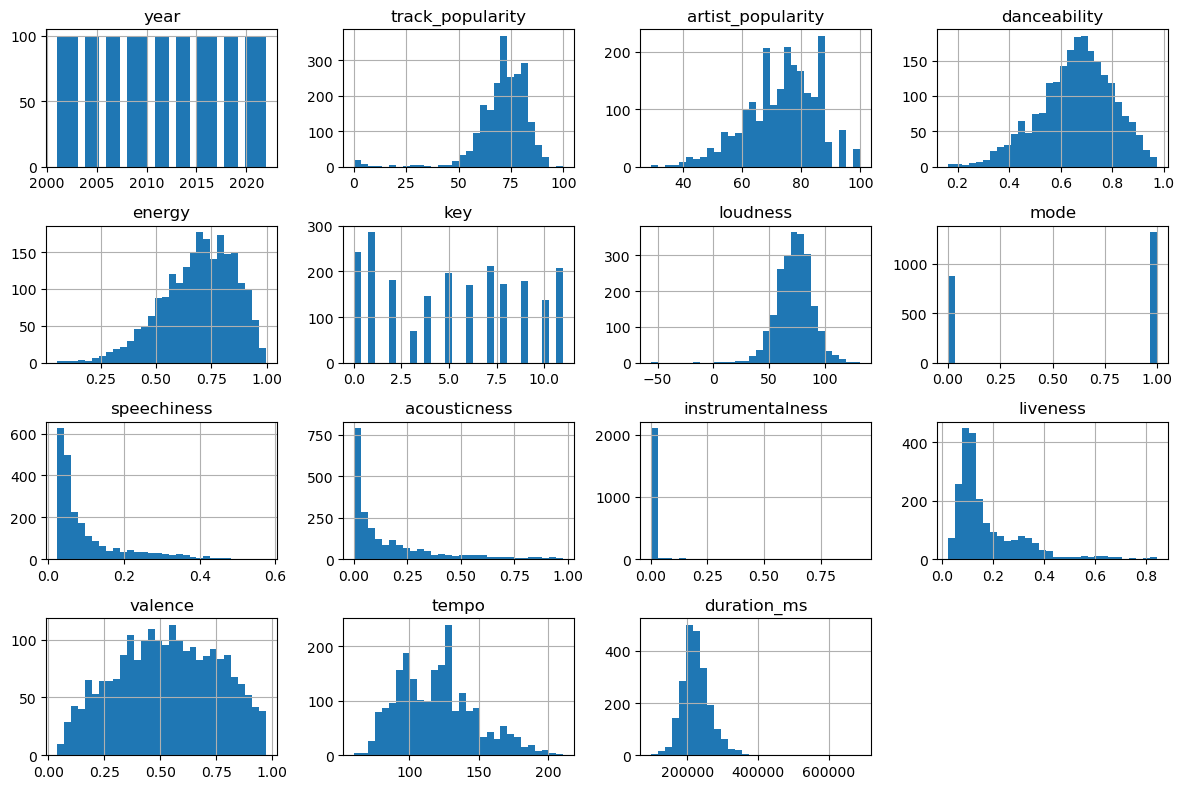

In [6]:
import matplotlib.pyplot as plt

# histograms for all numeric columns
df_clean.select_dtypes(include="number").hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [7]:
df_clean.describe()

,year,track_popularity,artist_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000,2199.000000
mean,2011.503411,71.187358,73.322874,0.660212,0.690250,5.262392,72.909050,0.600273,0.099313,0.159334,0.013042,0.173152,0.530696,120.449362,224997.773079
std,6.345157,12.377678,12.039380,0.141360,0.165072,3.622898,15.657326,0.489954,0.093476,0.206262,0.080926,0.132251,0.226954,27.711208,41938.704998
min,2001.000000,0.000000,29.000000,0.162000,0.051900,0.000000,-56.000000,0.000000,0.022500,0.000013,0.000000,0.021000,0.037700,60.019000,97393.000000
25%,2006.000000,66.000000,66.000000,0.573000,0.585000,2.000000,63.000000,0.000000,0.038600,0.016500,0.000000,0.090500,0.357000,98.310500,199542.000000
50%,2012.000000,73.000000,75.000000,0.671000,0.709000,5.000000,73.000000,1.000000,0.058100,0.069700,0.000000,0.120000,0.534000,120.000000,220734.000000
75%,2017.000000,79.000000,83.000000,0.759500,0.816000,8.000000,83.000000,1.000000,0.118000,0.223000,0.000049,0.218500,0.716000,137.049500,245326.500000
max,2022.000000,100.000000,100.000000,0.975000,0.999000,11.000000,132.000000,1.000000,0.576000,0.978000,0.925000,0.843000,0.974000,210.857000,688453.000000


<h5>Instrumentalness has too little variance. We may not use it in our models</h5>

In [8]:
df_clean['instrumentalness'].value_counts()

0.000000    1216
0.000016       5
0.000011       5
0.000001       5
0.130000       4
            ... 
0.000009       1
0.000406       1
0.000071       1
0.000004       1
0.006930       1
Name: instrumentalness, Length: 805, dtype: int64

<h5>Look at the distribution for 4 non-numerical columns. We may not use the track_name, artist_name and album columns as their cardinality is too high. In the next notebook we used the artist_genre column for the tree-based models.</h5>

In [9]:
print(df_clean['track_name'].value_counts(), '\n')
print(df_clean['artist_name'].value_counts(), '\n')
print(df_clean['album'].value_counts(), '\n')
print(df_clean['artist_genres'].value_counts(), '\n')

Home                                               5
Sorry                                              4
Paradise                                           3
Mercy                                              3
A Thousand Years                                   3
                                                  ..
Love Song                                          1
Dangerous                                          1
All Summer Long                                    1
4 Minutes (feat, Justin Timberlake & Timbaland)    1
Thousand Miles                                     1
Name: track_name, Length: 2027, dtype: int64 

Drake              32
Taylor Swift       31
Rihanna            27
BeyoncÃ©           22
Ariana Grande      22
                   ..
Vampire Weekend     1
Saving Abel         1
David Archuleta     1
Metro Station       1
Gunna               1
Name: artist_name, Length: 846, dtype: int64 

18 Months                                      8
25                              

<h5>We can see that only too variables are highly correlated (energy and loudness)</h5>

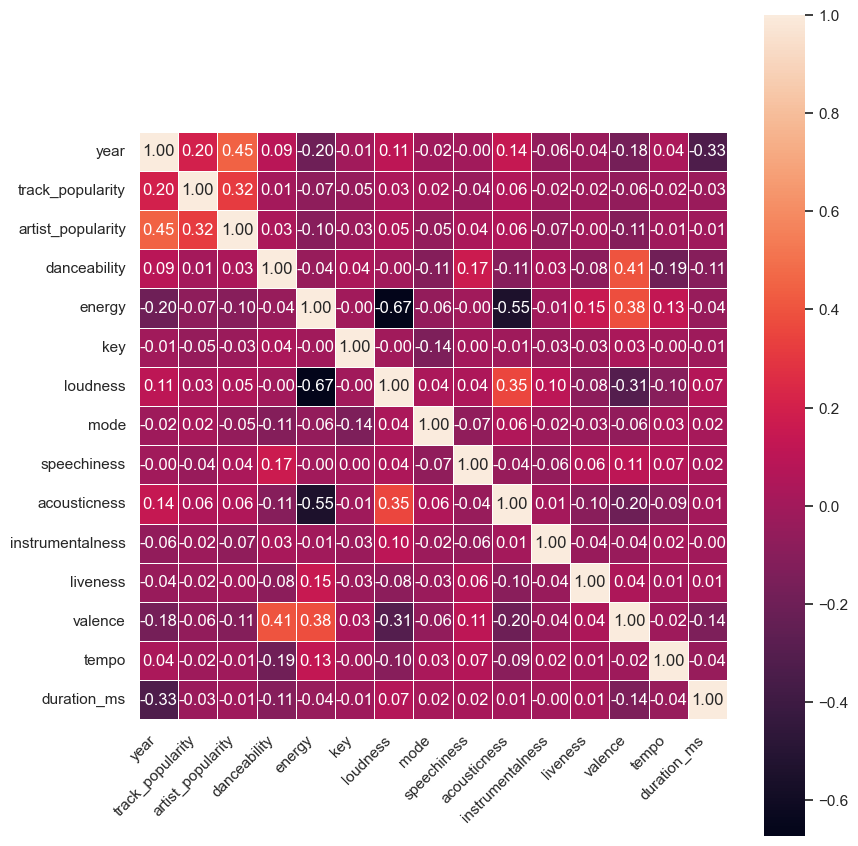

In [10]:
# Use only numeric columns from the cleaned df
num_df = df_clean.select_dtypes(include="number")
corr = num_df.corr()

# Auto-size: scale with number of variables, clamp to a reasonable range
n = corr.shape[0]
side = max(6, min(0.6 * n, 20))   # between 6" and 20"
sns.set(font_scale=1 if n > 12 else 1.1)

fig, ax = plt.subplots(figsize=(side, side))
sns.heatmap(
    corr,
    annot=True, fmt=".2f",
    linewidths=0.5,
    square=True,
    ax=ax
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


<h2>Dimension Reduction</h2>

<h5>We only use numeric features for dimension reduction</h5>

In [11]:
num_df = df_clean.select_dtypes(include="number").drop(columns=['track_popularity'])


<h5>We scale them with the StandardScaler</h5>

In [12]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler().fit(num_df)
X_std = ss.transform(num_df)

<h5>We run Factor Analysis and plot the explained variance vs factors plot and the scree plot</h5>

In [13]:
from sklearn.decomposition import FactorAnalysis

sklearn_fa = FactorAnalysis(len(num_df.columns)) # This argument tells it how many factors to extract: initially we use all variables
Y_sklearn = sklearn_fa.fit_transform(X_std)

In [14]:
loadings = sklearn_fa.components_
explained_variance_fa = np.var(loadings, axis=1)
explained_variance_ratio = explained_variance_fa / np.sum(explained_variance_fa)

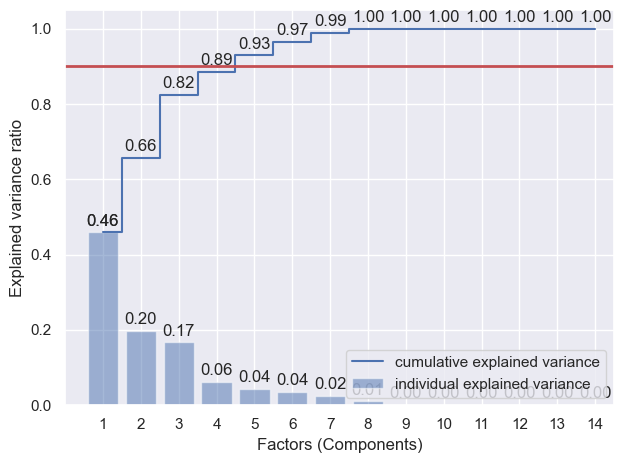

In [15]:
plt.bar(range(1,sklearn_fa.n_components+1), explained_variance_ratio, alpha=0.5, align='center',label='individual explained variance')
plt.step(range(1,sklearn_fa.n_components+1), [explained_variance_ratio[:y].sum() for y in range(1,sklearn_fa.n_components+1)], where='mid',label='cumulative explained variance')
plt.axhline(y=0.90, linewidth=2, color = 'r')
plt.ylabel('Explained variance ratio')
plt.xlabel('Factors (Components)')
for i, ratio in enumerate(explained_variance_ratio):
    plt.text(i+1, ratio + 0.01, f'{ratio:.2f}', ha='center', va='bottom')
for i, ratio in enumerate([explained_variance_ratio[:y].sum() for y in range(1,sklearn_fa.n_components+1)]):
    plt.text(i+1, ratio + 0.01, f'{ratio:.2f}', ha='center', va='bottom')

plt.xlim([0, sklearn_fa.n_components+0.5])
plt.xticks(range(1, sklearn_fa.n_components + 1))
plt.legend(loc='best')
plt.tight_layout()


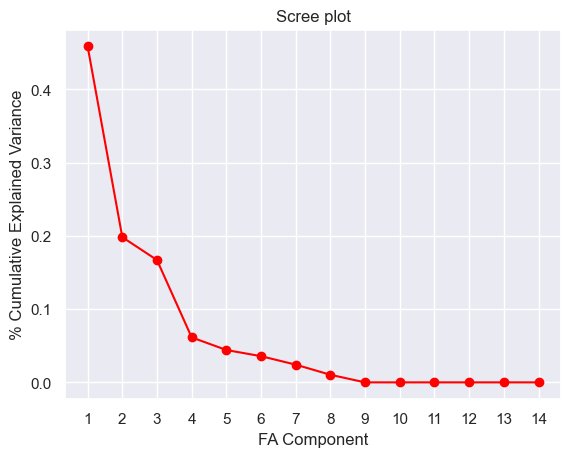

In [16]:
# Scree plot
plt.plot(
    range(1,len(explained_variance_ratio )+1),
    explained_variance_ratio,
    c='red', marker='o'
)
plt.xticks(range(1, len(explained_variance_ratio) + 1))
plt.xlabel('FA Component')
plt.ylabel('% Cumulative Explained Variance')
plt.title('Scree plot')
plt.show()

<h5>We decide to retain 81% of variance with 3 factors</h5>

In [17]:
VARIANCE_TO_KEEP = 0.81 # that would mean 3 componentes in our case
keep_recommend = [explained_variance_ratio[:y].sum()>VARIANCE_TO_KEEP for y in range(1,sklearn_fa.n_components+1)].count(False)
print("Number of components to keep to retain %s%% of the variance:" % (100*VARIANCE_TO_KEEP), keep_recommend, "out of the original", sklearn_fa.n_components)
n_components = keep_recommend

Number of components to keep to retain 81.0% of the variance: 2 out of the original 14


In [18]:
print(X_std.shape, X_std.dtype)


(2199, 14) float64


In [19]:
print("NaNs:", np.isnan(X_std).any())
print("Infs:", np.isinf(X_std).any())

NaNs: False
Infs: False


<h5>We run Factor Analysis for 3 factors only</h5>

In [20]:
from sklearn.decomposition import FactorAnalysis

sklearn_fa_final = FactorAnalysis(
    n_components=n_components,
    max_iter=100,      # default is 1000, which is overkill here
    tol=1e-2,          # OK for most use cases
    random_state=0,
    # verbose=1
)

Y_sklearn_final = sklearn_fa_final.fit_transform(X_std)


<PYTHON_ENV>/lib/python3.11/site-packages/sklearn/decomposition/_factor_analysis.py:296: ConvergenceWarning: FactorAnalysis did not converge. You might want to increase the number of iterations.
  warnings.warn(


As we can see, labeling these is not intuitive.

In [21]:
# The following shows Factor loadings = correlations between variables and factors
print ("")
print ("Factor loadings:")

pd.set_option('display.float_format', '{:.4f}'.format)

dfloadings=pd.DataFrame(
    data    = sklearn_fa_final.components_,
    columns = num_df.columns,
)

index_list=[]
for n in range(n_components):
    index_list.append("F"+str(n+1))

dfloadings.index = index_list

# Hide low values so that the table is clearer
dfloadings.T.where(abs(dfloadings.T) > 0.3  , "")  # we hide values lower than 0.3 to better display the relations


Factor loadings:


,F1,F2
year,0.6419,-0.7132
artist_popularity,0.3119,-0.3370
danceability,,
energy,-0.8385,-0.4708
key,,
loudness,0.5886,0.3786
mode,,
speechiness,,
acousticness,0.5018,
instrumentalness,,


The communalities are only high for 3 variables

In [22]:
# Communalities
commun=[]

for col in dfloadings.columns:
    commun.append((dfloadings.iloc[0:n_components][col]**2).sum())

dfcommun = pd.DataFrame(commun,index=dfloadings.columns, columns=["Communalities"])
dfcommun.sort_values("Communalities", ascending=False)

,Communalities
energy,0.9247
year,0.9208
loudness,0.4898
acousticness,0.3171
artist_popularity,0.2109
valence,0.1692
duration_ms,0.1278
liveness,0.0229
tempo,0.0219
danceability,0.0075


Even after running an orthogonal rotation like varimax. Labeling our factors is not straightforward at all.

In [23]:
# !pip install factor_analyzer
from factor_analyzer import FactorAnalyzer

fa_rot = FactorAnalyzer(n_factors=n_components, rotation="varimax")
Y_sklearn_rot = fa_rot.fit_transform(X_std)

k = fa_rot.loadings_.shape[1]  # n_factors actually fit
df_varimax = pd.DataFrame(
    fa_rot.loadings_,
    index=num_df.columns,
    columns=[f"F{i+1}" for i in range(k)]
)


<PYTHON_ENV>/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
<PYTHON_ENV>/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [24]:
df_varimax.where(abs(df_varimax) > 0.3  , "")

,F1,F2
year,,0.9794
artist_popularity,,0.3961
danceability,,
energy,-0.9282,
key,,
loudness,0.6910,
mode,,
speechiness,,
acousticness,0.5519,
instrumentalness,,


<h2>Output clean Dataframe (without Dimension Reduction)</h2>

In the `EDA` stage we saw that only two variables were correlated (energy and loudness). Doing Factor Analysis has not yielded good results so we don't output those results for the dataset we will use in the next notebook.

In [25]:
out_path = "../data/spotify_clean.csv"
df_clean.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

Saved: spotify_clean.csv


In [26]:
df_clean

,year,track_name,track_popularity,album,artist_name,artist_genres,artist_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,2001,It Wasn't Me,81,Hot Shot,Shaggy,['pop rap'; 'reggae fusion'],71,0.8530,0.6060,0.0000,66.0000,1.0000,0.0713,0.0561,0.0000,0.3130,0.6540,94.7590,227600.0000
1,2001,Survivor,73,Survivor,Destiny's Child,['dance pop'; 'girl group'; 'pop'; 'r&b'; 'urb...,69,0.5140,0.9110,1.0000,30.0000,0.0000,0.4100,0.0559,0.0000,0.7750,0.6190,161.1090,254027.0000
2,2001,Stan,84,The Marshall Mathers LP,Eminem,['detroit hip hop'; 'hip hop'; 'rap'],88,0.7800,0.7680,6.0000,63.0000,0.0000,0.2380,0.0371,0.0000,0.5180,0.5070,80.0630,404107.0000
3,2001,Can't Get You out of My Head,80,Fever,Kylie Minogue,['australian dance'; 'australian pop'; 'dance ...,71,0.7660,0.5630,9.0000,87.0000,0.0000,0.0339,0.0263,0.6830,0.1150,0.9640,126.0070,230640.0000
4,2001,Lady Marmalade - Single Edit,70,Lady Marmalade,Christina Aguilera,['dance pop'; 'pop'],75,0.7540,0.8110,5.0000,56.0000,1.0000,0.0561,0.0185,0.0000,0.6540,0.6390,109.9020,267960.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2194,2022,Die Hard,79,"Mr, Morale & The Big Steppers",Kendrick Lamar,['conscious hip hop'; 'hip hop'; 'rap'; 'west ...,86,0.7750,0.7360,1.0000,90.0000,0.0000,0.2470,0.3190,0.0012,0.1270,0.3620,100.9880,239027.0000
2195,2022,Big Energy,69,777,Latto,['trap queen'],85,0.9370,0.7930,11.0000,64.0000,0.0000,0.1150,0.0453,0.0000,0.3410,0.7940,106.0220,172540.0000
2196,2022,Doja,86,Doja,Central Cee,['melodic drill'],82,0.9110,0.5730,6.0000,87.0000,1.0000,0.2880,0.3800,0.0000,0.4030,0.9720,140.0400,97393.0000
2197,2022,"pushin P (feat, Young Thug)",77,DS4EVER,Gunna,['atl hip hop'; 'melodic rap'; 'rap'; 'trap'],84,0.7730,0.4220,1.0000,66.0000,0.0000,0.1870,0.0078,0.0069,0.1290,0.4880,77.5020,136267.0000
